<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01.) Exploratory Data Analysis

Exploring the datasets of California property sale prices using CRMLSold datasets spanning from [2025_02] to [2026_04].

## Goals for this Notebook
1.   Load, filter, and clean datasets to prepare for analysis.
2.   Explore distributions of ClosePrice (target variable), LivingArea, Bedrooms, Bathrooms, and LotSize(SquareFeet)
3.   Begin basic analysis with basic EDA plots.



In [ ]:
# read data from Google Drive
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Projects/IDX Exchange Data/"

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Datasets

Loading datasets spanning from [2025_02-2026_04] into a single raw data frame.

In [ ]:
#displays max columns to 80 which is total columns in our dataset
pd.set_option('display.max_columns', 85)
#read dataset from 2026_04
df = pd.read_csv(path + "CRMLSSold202604.csv")


# Read all datasets from 2025_02 to 2026_04
dates = pd.period_range("202502", "202604", freq="M").astype(str).str.replace("-", "", regex=False)
raw_data = pd.DataFrame({})


for month in dates:
  iterative_month = ("CRMLSSold" + month + ".csv")
  iter_month_df = pd.read_csv(path + iterative_month, low_memory=False)
  iter_month_df["dataset"] = iterative_month
  raw_data = pd.concat([raw_data, iter_month_df])


display(raw_data.head(3))
print(f"Raw Shape: {raw_data.shape}")


,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,dataset,OriginatingSystemName,OriginatingSystemSubName
0,RanchoSoutheast,RanchoSoutheast,NaN,True,NaN,NaN,NaN,60000.0,526199946,cmark1018@yahoo.com,2025-02-21,35000.0,Chris,Mark,34.536780,-117.273839,0 Quantico Road,Land,NaN,35000.0,196,Far West Realty,KW Vision,NaN,Chris Mark,NaN,NaN,TRSUDAJAM,James,Sudarsono,NaN,NaN,NaN,526199946,APPV - Apple Valley,NaN,San Bernardino,Closed,NaN,NaN,NaN,NaN,NaN,0.6428,NaN,TriCounties,NaN,0.0,RS21140713,NaN,Apple Valley,NaN,NaN,NaN,2025-02-21,NaN,NaN,2022-01-10,2021-06-28,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28000.0,NaN,False,NaN,NaN,92307,0.0,28000.0,NaN,CRMLSSold202502.csv,NaN,NaN
1,InlandValleys,InlandValleys,NaN,False,NaN,NaN,NaN,550000.0,525585060,mozcorona@aol.com,2025-02-14,625000.0,MANUEL,ZAMORANO,33.938547,-117.239639,24255 Sunnymead Boulevard,Land,NaN,550000.0,1232,"KAREN PIERCE, BROKER","KAREN PIERCE, BROKER",NaN,MANUEL ZAMORANO,NaN,NaN,ivzamoman,MANUEL,ZAMORANO,NaN,NaN,NaN,525585060,259 - Moreno Valley,NaN,Riverside,Closed,NaN,NaN,NaN,NaN,NaN,0.9100,NaN,InlandValleys,NaN,24255.0,IV21138689,NaN,Moreno Valley,NaN,NaN,NaN,2025-02-14,NaN,NaN,2024-11-08,2021-06-25,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39640.0,NaN,False,NaN,NaN,92553,0.0,39640.0,NaN,CRMLSSold202502.csv,NaN,NaN
2,SanDiego,SanDiego,NaN,False,NaN,NaN,False,880000.0,497696903,lenskab@gmail.com,2025-02-11,875000.0,Lenska,Bracknell,32.765380,-117.043486,4750 Dana Dr,Residential,2340.0,880000.0,20,LENSKA Realty,Coldwell Banker West,NaN,Lenska Bracknell,NaN,NaN,809976,Sheetal,Gandhi,NaN,NaN,NaN,497696903,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,6.0,NaN,SingleFamilyResidence,NaN,La Mesa,PacificSouthwest,2021.0,4750.0,210000201,4.0,La Mesa,NaN,NaN,4.0,2025-02-11,NaN,NaN,2021-01-25,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN


Raw Shape: (324496, 81)


In [ ]:
# descriptions of every column present in the raw_data
description = pd.DataFrame({"1" : df.columns})
trestle = pd.read_csv(path + "Trestle_Property_Fields_Full.csv")
trestle_descriptions = pd.merge(description, trestle, left_on="1", right_on="Field", how='inner').drop(columns=["1", "Type", "Size"])
trestle_descriptions

,Field,Description
0,BuyerAgentAOR,The Buyer's Agent's Board or Association of RE...
1,ListAgentAOR,The Listing Agent's Board or Association of RE...
2,Flooring,A list of the type(s) of flooring found within...
3,ViewYN,The property has a view.
4,WaterfrontYN,The property is on the waterfront.
...,...,...
75,AssociationFee,A fee paid by the homeowner to the Home Owners...
76,LotSizeSquareFeet,The total square footage of the lot.
77,MiddleOrJuniorSchoolDistrict,The name of the junior or middle school distri...
78,OriginatingSystemName,The name of the Originating record provider.


## Restrict Analysis to Project Scope

Restrict analysis to:

*   `PropertyType = Residential`
*   `PropertySubType = SingleFamilyResidence`



In [ ]:
# Restricting analysis to the project scope
raw_scope_data = raw_data[(raw_data["PropertyType"] == "Residential") &
 (raw_data["PropertySubType"] == "SingleFamilyResidence")]

print(f"# of rows before restriction: {len(raw_data)}")
print(f"# of rows after restriction: {len(raw_scope_data)}")
print()


# Delete duplicate listings using ListingKey
print(f"# of duplicate listings: {raw_scope_data.duplicated(subset="ListingKey").sum()}")
unique_raw_scope_data = raw_scope_data.loc[~raw_scope_data.duplicated(subset=["ListingKey"])].reset_index(drop=True)
print(f"# of rows after deleting duplicate listings: {len(unique_raw_scope_data)}")
display(unique_raw_scope_data)

# of rows before restriction: 324496
# of rows after restriction: 162567

# of duplicate listings: 113
# of rows after deleting duplicate listings: 162454


,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,dataset,OriginatingSystemName,OriginatingSystemSubName
0,SanDiego,SanDiego,NaN,False,NaN,NaN,False,880000.0,497696903,lenskab@gmail.com,2025-02-11,875000.0,Lenska,Bracknell,32.765380,-117.043486,4750 Dana Dr,Residential,2340.0,880000.0,20,LENSKA Realty,Coldwell Banker West,NaN,Lenska Bracknell,NaN,NaN,809976,Sheetal,Gandhi,NaN,NaN,NaN,497696903,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,6.0,NaN,SingleFamilyResidence,NaN,La Mesa,PacificSouthwest,2021.0,4750.0,210000201,4.0,La Mesa,NaN,NaN,4.0,2025-02-11,NaN,NaN,2021-01-25,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
1,SanDiego,SanDiego,NaN,False,NaN,NaN,False,875000.0,497696407,lenskab@gmail.com,2025-02-14,875000.0,Lenska,Bracknell,32.765038,-117.043568,4740 Dana Dr,Residential,2165.0,875000.0,9,LENSKA Realty,LENSKA Realty,NaN,Lenska Bracknell,NaN,NaN,SAND-649841,Lenska,Bracknell,NaN,NaN,NaN,497696407,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.0,NaN,SingleFamilyResidence,NaN,La Mesa,SanDiego,2021.0,4740.0,210000200,4.0,La Mesa,NaN,NaN,5.0,2025-02-14,NaN,NaN,2021-01-14,2021-01-05,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
2,SanDiego,SanDiego,NaN,False,NaN,NaN,False,849000.0,486616176,lenskab@gmail.com,2025-02-18,849000.0,Lenska,Bracknell,32.765031,-117.043252,4730 Dana Dr,Residential,2158.0,849000.0,91,LENSKA Realty,Heritage Homes San Diego,NaN,Lenska Bracknell,NaN,NaN,SAND-693007,Jason,Piske,NaN,NaN,NaN,486616176,91942 - La Mesa,NaN,San Diego,Closed,NaN,True,4.0,NaN,SingleFamilyResidence,NaN,La Mesa,SanDiego,2021.0,4730.0,200049530,3.0,La Mesa,NaN,NaN,4.0,2025-02-18,NaN,NaN,2021-01-25,2020-10-22,NaN,NaN,CA,NaN,NaN,False,1.0,NaN,One,NaN,NaN,NaN,False,2.0,NaN,91942,NaN,NaN,NaN,CRMLSSold202502.csv,NaN,NaN
3,SouthBay,SouthBay,Carpet,True,NaN,True,False,1100000.0,1108119618,elaine@elainemallon.com,2025-02-28,1100000.0,Elaine,Mallon,33.724000,-118.294924,2211 S Cabrillo Avenue,Residential,2545.0,1100000.0,0,Rodeo Realty,Rodeo Realty,NaN,Elaine Mallon,NaN,NaN,sbmallela,Elaine,Mallon,NaN,NaN,NaN,1108119618,183 - Vista Del Oro,NaN,Los Angeles,Closed,NaN,False,3.0,NaN,SingleFamilyResidence,0.1033,NaN,SouthBay,1962.0,2211.0,SB24235361,3.0,San Pedro,NaN,NaN,4.0,2025-02-28,NaN,NaN,2025-01-10,2024-11-18,NaN,NaN,CA,NaN,NaN,True,2.0,San Pedro,Two,NaN,4501.00,4.0,False,2.0,Los Angeles Unified,90731,0.0,4501.0,NaN,CRMLSSold202502.csv,NaN,NaN
4,ContraCosta,ContraCosta,Carpet,NaN,NaN,NaN,False,760000.0,1108119338,sabine.larsen@redfin.com,2025-02-28,760000.0,Sabine,Larsen,37.687556,-122.150114,15216 Edgemoor St,Residential,1692.0,760000.0,0,Redfin,Legacy Real Estate & Assoc.,NaN,Sabine Larsen,NaN,NaN,CCBE-206516251,Kristy,Peixoto,NaN,NaN,NaN,1108119338,NaN,NaN,Alameda,Closed,Na

# Deciding Key Columns

In [ ]:
# DECIDING WHICH COLUMNS TO REMOVE

key_data = unique_raw_scope_data[[#'index', 'BuyerAgentAOR', 'ListAgentAOR',
                                  'Flooring', #'ViewYN', 'WaterfrontYN',
       #'BasementYN', 'PoolPrivateYN', 'OriginalListPrice',
    'ListingKey',
       #'ListAgentEmail',
    'CloseDate',
    'ClosePrice', #'ListAgentFirstName',
       #'ListAgentLastName',
    'Latitude',
    'Longitude',
    'UnparsedAddress',
       #'PropertyType',
    'LivingArea',
    'ListPrice',
    'DaysOnMarket',
      #  'ListOfficeName', 'BuyerOfficeName', 'CoListOfficeName',
      #  'ListAgentFullName', 'CoListAgentFirstName', 'CoListAgentLastName',
      #  'BuyerAgentMlsId', 'BuyerAgentFirstName', 'BuyerAgentLastName',
      #  'FireplacesTotal', 'AssociationFeeFrequency', 'AboveGradeFinishedArea',
      #  'ListingKeyNumeric', 'MLSAreaMajor', 'TaxAnnualAmount',
      #  'CountyOrParish', 'MlsStatus', 'ElementarySchool', 'AttachedGarageYN',
      #  'ParkingTotal', 'BuilderName', 'PropertySubType', 'LotSizeAcres',
      #  'SubdivisionName', 'BuyerOfficeAOR',
    'YearBuilt', #'StreetNumberNumeric',
      #  'ListingId',
    'BathroomsTotalInteger',#
    'City', #'TaxYear',
       #'BuildingAreaTotal',
    'BedroomsTotal', #'ContractStatusChangeDate',
       #'ElementarySchoolDistrict', 'CoBuyerAgentFirstName',

    'PurchaseContractDate',
      #'ListingContractDate', 'BelowGradeFinishedArea',
      #  'BusinessType', 'StateOrProvince', 'CoveredSpaces',
      #  'MiddleOrJuniorSchool', 'FireplaceYN', 'Stories', 'HighSchool',
      #  'Levels', 'LotSizeDimensions', 'LotSizeArea', 'MainLevelBedrooms',
      #  'NewConstructionYN', 'GarageSpaces', 'HighSchoolDistrict', 'PostalCode',
      #  'AssociationFee',
    'LotSizeSquareFeet', #'MiddleOrJuniorSchoolDistrict', 'dataset'
      #  'OriginatingSystemName', 'OriginatingSystemSubName'
       ]].copy()

key_data.head(3)

,Flooring,ListingKey,CloseDate,ClosePrice,Latitude,Longitude,UnparsedAddress,LivingArea,ListPrice,DaysOnMarket,YearBuilt,BathroomsTotalInteger,City,BedroomsTotal,PurchaseContractDate,LotSizeSquareFeet
0,NaN,497696903,2025-02-11,875000.0,32.765380,-117.043486,4750 Dana Dr,2340.0,880000.0,20,2021.0,4.0,La Mesa,4.0,2021-01-25,NaN
1,NaN,497696407,2025-02-14,875000.0,32.765038,-117.043568,4740 Dana Dr,2165.0,875000.0,9,2021.0,4.0,La Mesa,5.0,2021-01-14,NaN
2,NaN,486616176,2025-02-18,849000.0,32.765031,-117.043252,4730 Dana Dr,2158.0,849000.0,91,2021.0,3.0,La Mesa,4.0,2021-01-25,NaN


In [ ]:
key_data.dtypes

key_data["CloseDate"] = pd.to_datetime(key_data["CloseDate"], errors = 'coerce', format='%Y-%m-%d')
key_data["PurchaseContractDate"] = pd.to_datetime(key_data["PurchaseContractDate"], errors = 'coerce', format='%Y-%m-%d')
key_data["YearBuilt"] = key_data["YearBuilt"].astype('Int64')

# Distribution Plots

Taking a look at our numerical columns. Use univariate analysis.

In [ ]:
key_data.drop(["ListingKey", "CloseDate", "Latitude", "Longitude", "PurchaseContractDate", "Flooring"], axis=1).describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,25%,50%,75%,99%,max
ClosePrice,162454.0,1330773.426607,7601264.34629,0.0,625000.0,890000.0,1423791.75,6400000.0,989500000.0
LivingArea,162367.0,2045.131788,1039.033988,0.0,1384.0,1816.0,2437.0,5654.68,56500.0
ListPrice,162454.0,1265024.70839,1591761.986962,8000.0,625000.0,893845.0,1399800.0,6500000.0,137500000.0
DaysOnMarket,162454.0,39.719539,52.789813,-265.0,8.0,19.0,52.0,248.0,2177.0
YearBuilt,162345.0,1975.872414,27.651142,1776.0,1956.0,1976.0,1998.0,2025.0,2026.0
BathroomsTotalInteger,162435.0,2.630357,1.136049,0.0,2.0,2.0,3.0,6.0,45.0
BedroomsTotal,162454.0,3.488391,0.971444,0.0,3.0,3.0,4.0,6.0,45.0
LotSizeSquareFeet,159623.0,358987.344653,17731021.636475,0.0,5663.0,7280.0,10454.0,265064.66,2087220960.0


Keep in mind that some columns will have null values or values that do not make sense given the context of our data (i.e. we can see that the minimum number of days on the market is -265). In week 3, we will work on flagging and removing/imputing these values

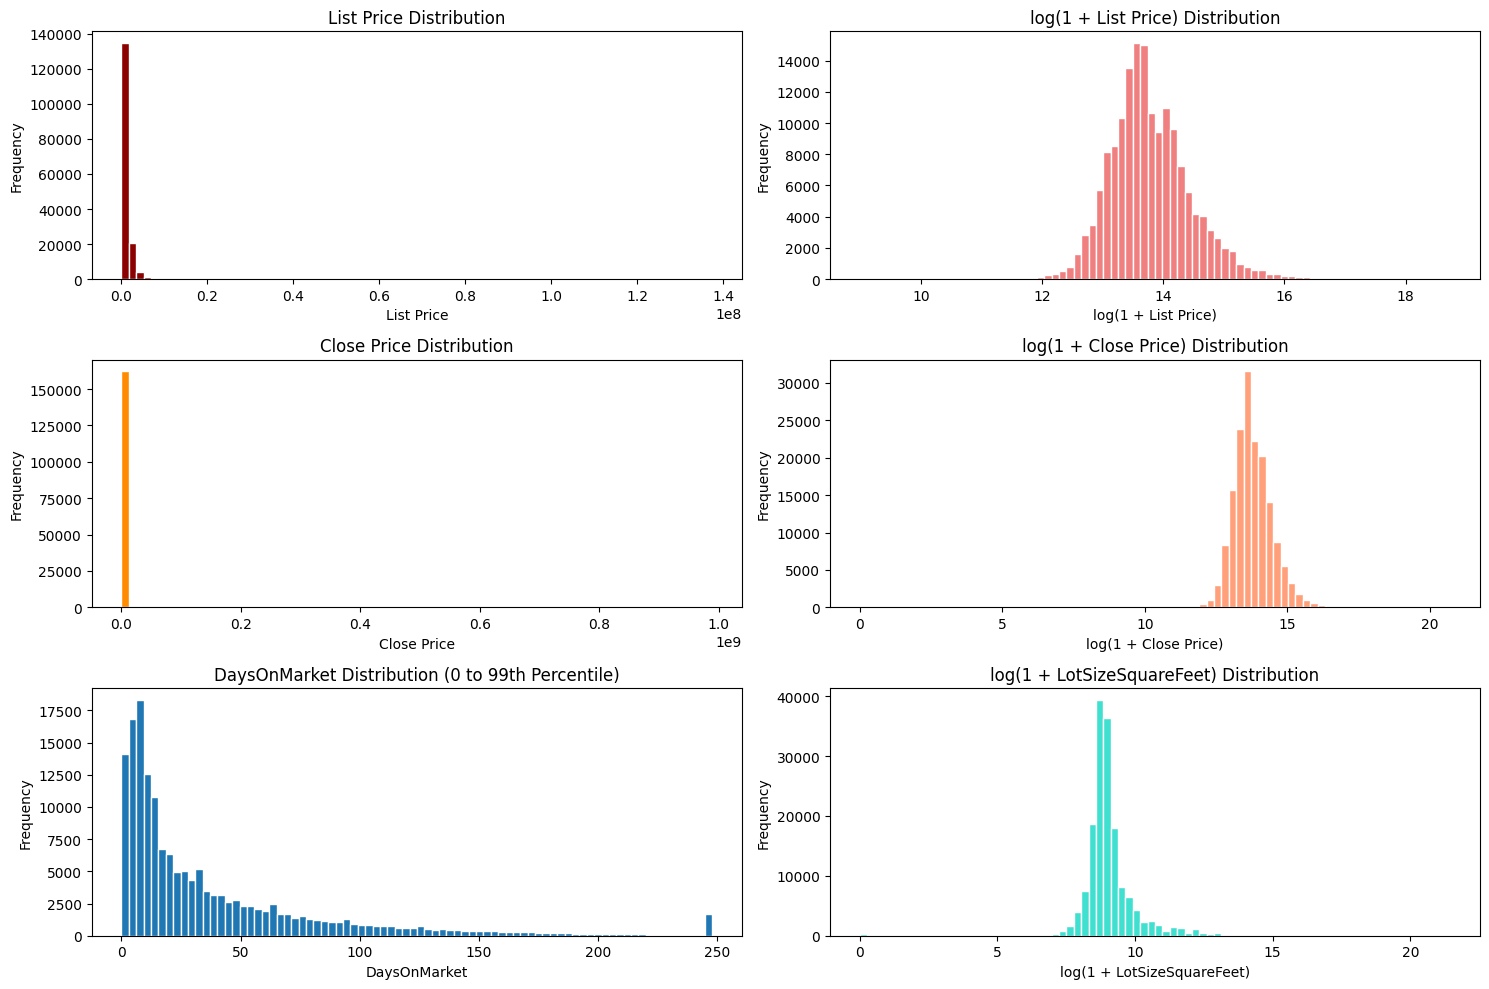

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))

key_data["ListPrice"].dropna().plot(kind='hist', bins=80, ax=axes[0,0], color='darkred', edgecolor='white')
axes[0,0].set_xlabel("List Price")
axes[0,0].set_title("List Price Distribution")

np.log1p(key_data["ListPrice"]).dropna().plot(kind='hist', bins=80, ax=axes[0,1], color='lightcoral', edgecolor='white')
axes[0,1].set_xlabel("log(1 + List Price)")
axes[0,1].set_title("log(1 + List Price) Distribution")


key_data["ClosePrice"].dropna().plot(kind='hist', bins=80, ax=axes[1,0], color='darkorange', edgecolor='white')
axes[1,0].set_xlabel("Close Price")
axes[1,0].set_title("Close Price Distribution")

np.log1p(key_data["ClosePrice"]).dropna().plot(kind='hist', bins=80, ax=axes[1,1], color='lightsalmon', edgecolor='white')
axes[1,1].set_xlabel("log(1 + Close Price)")
axes[1,1].set_title("log(1 + Close Price) Distribution")


key_data["DaysOnMarket"].clip(lower=0, upper=key_data["DaysOnMarket"].quantile(0.99)).plot(kind='hist', bins=80, ax=axes[2,0], edgecolor='white')
axes[2,0].set_xlabel("DaysOnMarket")
axes[2,0].set_title("DaysOnMarket Distribution (0 to 99th Percentile)")

np.log1p(key_data["LotSizeSquareFeet"]).dropna().plot(kind='hist', bins=80, ax=axes[2,1], color='turquoise', edgecolor='white')
axes[2,1].set_xlabel("log(1 + LotSizeSquareFeet)")
axes[2,1].set_title("log(1 + LotSizeSquareFeet) Distribution")


plt.tight_layout()
plt.show()

# Feature Relationships

what to look at

listprice vs close price (listings that receive many competing offers in a short window)
- compare alongside days on market
- conversely a large gap between list and close price (downward) signals an overpriced listing

sale to list ratio
- close price / list price
- ratio above 1.0 signals competitive seller's market

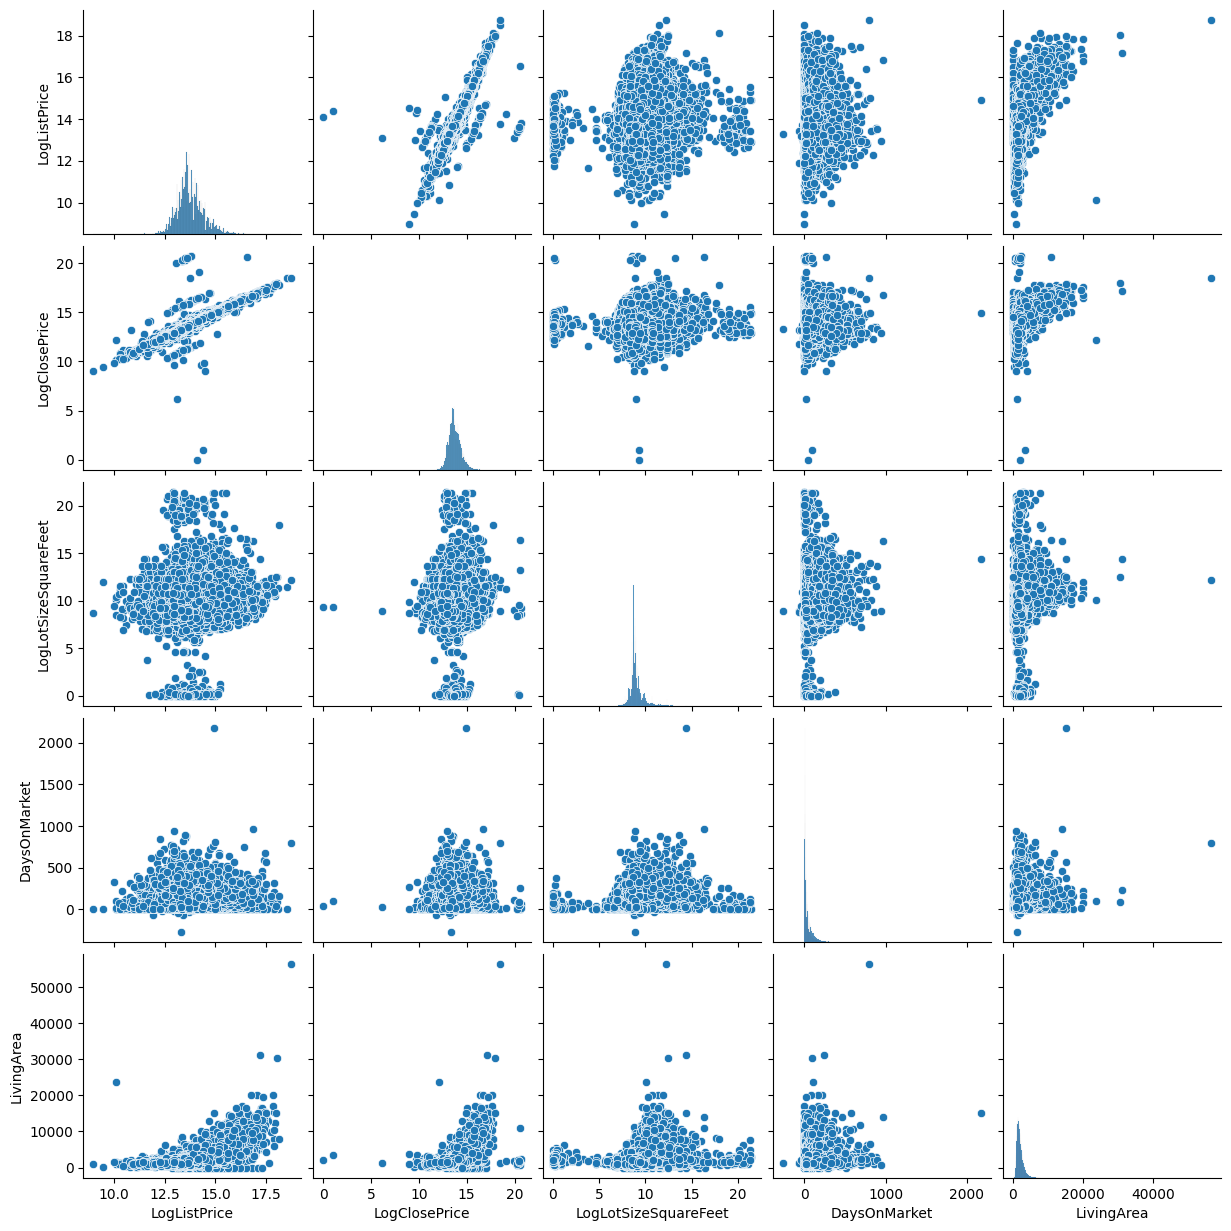

In [ ]:
logged_data = key_data
logged_data['LogClosePrice'] = np.log1p(key_data["ClosePrice"])
logged_data['LogListPrice'] = np.log1p(key_data["ListPrice"])
logged_data['LogLotSizeSquareFeet'] = np.log1p(key_data["LotSizeSquareFeet"])
logged_data['LogLivingArea'] = np.log1p(key_data["LivingArea"])


sns.pairplot(logged_data,
             vars=['LogListPrice', 'LogClosePrice', 'LogLotSizeSquareFeet', 'DaysOnMarket', 'LivingArea'])
plt.show()

We want to showcase ClosePrice vs ListPrice. Upon first inspection, we have a lot of overlap between points. Let's sample our dataset to have a clearer view of the relationship happening.



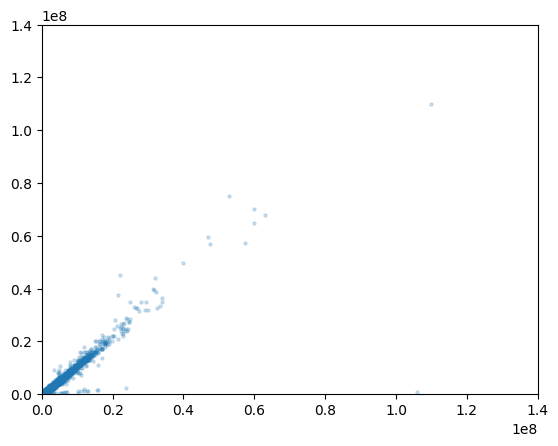

In [ ]:
sample_data = key_data.sample(frac=0.5, random_state=42)

ax = plt.scatter(x="ClosePrice", y="ListPrice", data=sample_data, alpha=0.2, s=5)

plt.plot([0, 0], [10**8, 10**8], color="black", linewidth=2)
plt.xlim(0, 1.4*10**8)
plt.ylim(0, 1.4*10**8)
plt.show()

,count,mean,std,min,25%,50%,75%,99%,max
SaleToListRatio,162454.0,1.091322,9.217808,0.0,0.974212,1.0,1.017857,1.277262,1074.981402


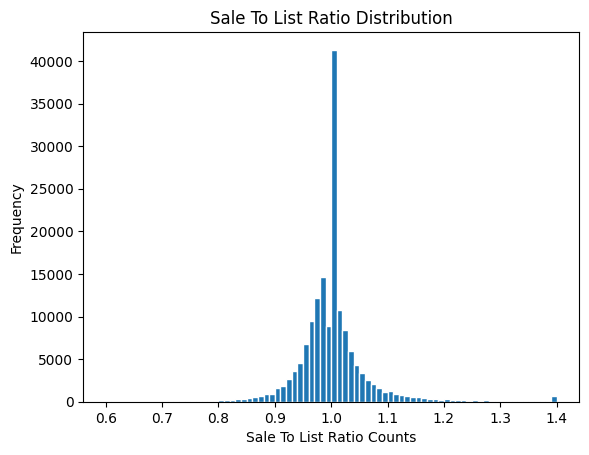

In [ ]:
key_data["SaleToListRatio"] = key_data["ClosePrice"] / key_data["ListPrice"]
display(key_data["SaleToListRatio"].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).to_frame().T)

ax = key_data["SaleToListRatio"].clip(lower=0.6, upper=1.4).plot(kind='hist',bins=80, edgecolor="white");
ax.set_title("Sale To List Ratio Distribution")
ax.set_xlabel("Sale To List Ratio Counts");

Median is **1.0** which suggests a balanced market, i.e. most homes are sold for asking price. Utilizing `ListPrice` will be extremely important for predicting `ClosePrice`.

Next, compare key features to ClosePrice.

In [ ]:
key_data.head(3)

,Flooring,ListingKey,CloseDate,ClosePrice,Latitude,Longitude,UnparsedAddress,LivingArea,ListPrice,DaysOnMarket,YearBuilt,BathroomsTotalInteger,City,BedroomsTotal,PurchaseContractDate,LotSizeSquareFeet,LogClosePrice,LogListPrice,LogLotSizeSquareFeet,LogLivingArea,SaleToListRatio
0,NaN,497696903,2025-02-11,875000.0,32.765380,-117.043486,4750 Dana Dr,2340.0,880000.0,20,2021,4.0,La Mesa,4.0,2021-01-25,NaN,13.681980,13.687678,NaN,7.758333,0.994318
1,NaN,497696407,2025-02-14,875000.0,32.765038,-117.043568,4740 Dana Dr,2165.0,875000.0,9,2021,4.0,La Mesa,5.0,2021-01-14,NaN,13.681980,13.681980,NaN,7.680637,1.000000
2,NaN,486616176,2025-02-18,849000.0,32.765031,-117.043252,4730 Dana Dr,2158.0,849000.0,91,2021,3.0,La Mesa,4.0,2021-01-25,NaN,13.651816,13.651816,NaN,7.677400,1.000000


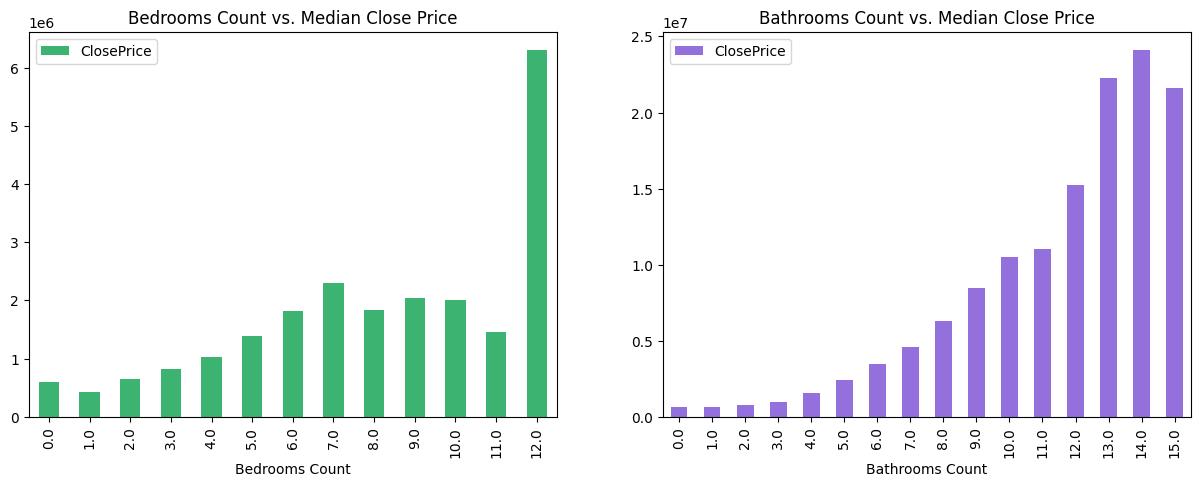

In [ ]:
bedrooms_median = key_data.where(key_data["BedroomsTotal"] <= 12).groupby("BedroomsTotal")["ClosePrice"].median()#.to_frame()
bathrooms_median = key_data.where(key_data["BathroomsTotalInteger"] <= 15).groupby("BathroomsTotalInteger")["ClosePrice"].median().to_frame()


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bedrooms_median = bedrooms_median.reset_index()
bedrooms_median.plot.bar(x = 'BedroomsTotal', y = 'ClosePrice', ax=axes[0], color='mediumseagreen')
axes[0].set_title("Bedrooms Count vs. Median Close Price")
axes[0].set_xlabel("Bedrooms Count")

bathrooms_median = bathrooms_median.reset_index()
bathrooms_median.plot.bar(x = 'BathroomsTotalInteger', y = 'ClosePrice', ax=axes[1], color='mediumpurple')
axes[1].set_title("Bathrooms Count vs. Median Close Price")
axes[1].set_xlabel("Bathrooms Count");

Text(0.5, 0, 'Living Area')

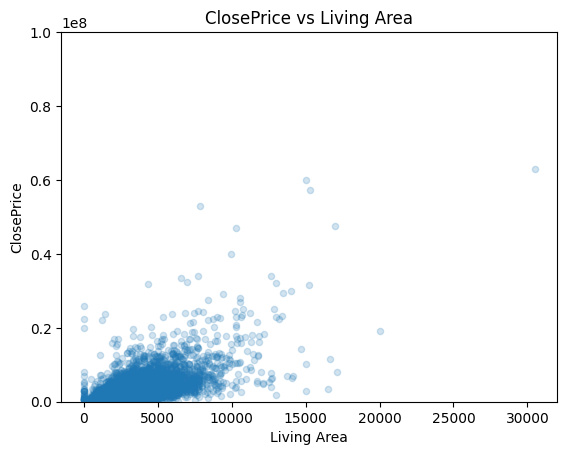

In [ ]:
sample_data.plot.scatter(x="LivingArea", y='ClosePrice', alpha=0.2)
plt.ylim(0, 10**8)
plt.title("ClosePrice vs Living Area")
plt.xlabel("Living Area")

,ClosePrice,ListPrice,LivingArea,BathroomsTotalInteger,BedroomsTotal,LotSizeSquareFeet
ClosePrice,1.000000,0.187810,0.120621,0.104464,0.065086,0.000424
ListPrice,0.187810,1.000000,0.640050,0.553393,0.320655,0.000869
LivingArea,0.120621,0.640050,1.000000,0.839383,0.655010,0.006503
BathroomsTotalInteger,0.104464,0.553393,0.839383,1.000000,0.660533,0.005914
BedroomsTotal,0.065086,0.320655,0.655010,0.660533,1.000000,0.005217
LotSizeSquareFeet,0.000424,0.000869,0.006503,0.005914,0.005217,1.000000


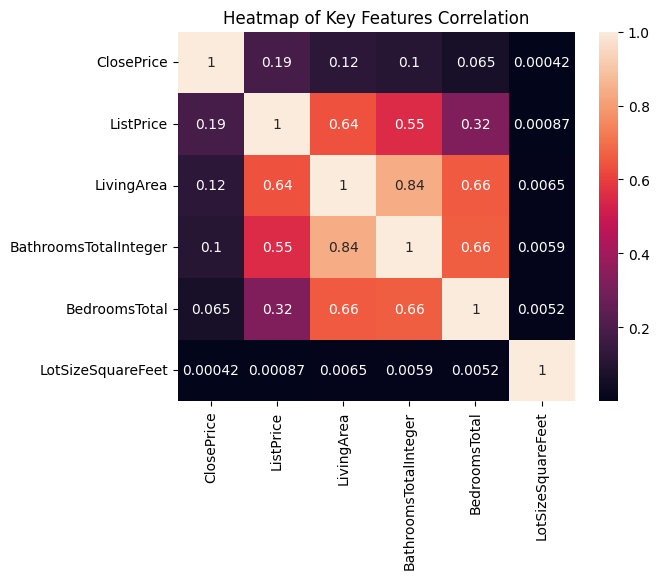

In [ ]:
key_corr = key_data[['ClosePrice', 'ListPrice',
                     'LivingArea', 'BathroomsTotalInteger',
                     'BedroomsTotal', 'LotSizeSquareFeet']].dropna().corr()
display(key_corr)

sns.heatmap(key_corr, annot=True)
plt.title("Heatmap of Key Features Correlation");

,count,mean,median
City,,,
Los Angeles,6753,"1,988,129.44",1365000.000000
San Diego,5590,"1,847,550.89",1200000.000000
Riverside,2510,"744,757.92",680000.000000
San Jose,2344,"1,806,092.67",1650000.500000
Oakland,2075,"1,094,237.88",950000.000000
Menifee,1863,"574,995.14",583000.000000
Long Beach,1645,"1,147,500.08",1000000.000000
Lancaster,1534,"489,791.56",474900.000000
Murrieta,1481,"804,685.46",710000.000000


,count,mean,median
City,,,
Glennville,1,"900,000,000.00",900000000.000000
Summerland,1,"13,955,000.00",13955000.000000
Atherton,40,"10,503,914.43",8400000.000000
Newport Coast,91,"10,170,121.98",7100000.000000
Montecito,23,"10,228,116.00",7000000.000000
Hidden Hills,13,"7,068,589.15",6000000.000000
Hillsborough,72,"6,727,665.11",5578000.000000
Corona Del Mar,140,"6,708,938.61",5500000.000000
Los Altos Hills,40,"5,903,041.88",5438000.000000


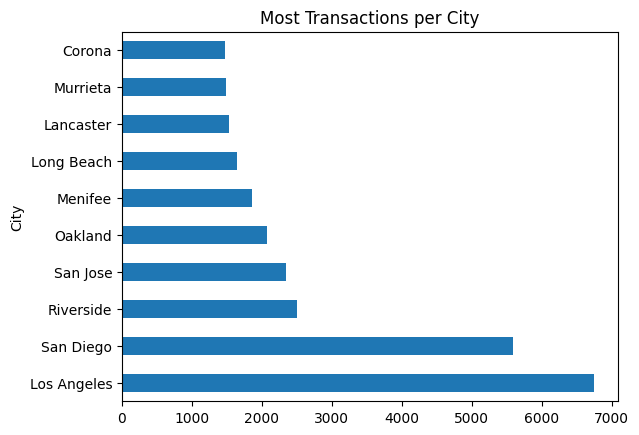

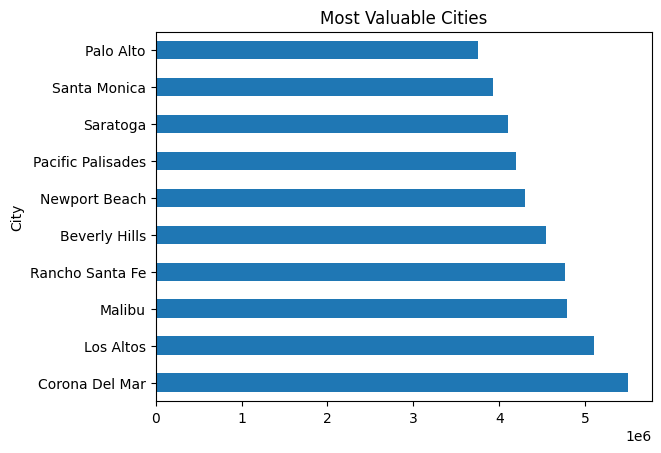

In [ ]:
city_stats = key_data.groupby("City")["ClosePrice"].agg(['count', 'mean', "median"])#.reset_index()
city_stats.style.format({'mean': '{:,.2f}'.format})

top_transactions = city_stats.sort_values("count", ascending=False)
top_value = city_stats.sort_values("median", ascending=False)

display(top_transactions.head(10).style.format({'mean': '{:,.2f}'.format}))
display(top_value.head(10).style.format({'mean': '{:,.2f}'.format}))

plt.title("Most Transactions per City")
plt.show(top_transactions['count'].head(10).plot(kind='barh'))

plt.title("Most Valuable Cities")
plt.show(top_value.query('count >= 100')["median"].head(10).plot(kind='barh'))

